# B110 Session 10: Customer Segmentation with K-Means

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HaoSophareth/b110-customer-clustering/blob/main/customer_clustering.ipynb)

This notebook reproduces the [Statistics Kingdom k-means calculator](https://www.statskingdom.com/cluster-analysis.html) analysis in Python:

- **Variables:** Avg_Order_Value, Months_Retained, Churn_Risk_Score
- **Scaling:** standardized, `(x - mean) / sample SD`, the same as the tool's "Standardized" option
- **K tested:** 2, 3, 4, plus an elbow curve over K = 1 to 8

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

URL = "https://raw.githubusercontent.com/HaoSophareth/b110-customer-clustering/main/customer_clustering_data.csv"
try:
    df = pd.read_csv("customer_clustering_data.csv")
except FileNotFoundError:
    df = pd.read_csv(URL)

df = df.dropna(subset=["Age"])
df.columns = ["ID", "Age", "Orders", "AOV", "Months", "Churn", "Channel", "CLV", "CAC", "CLV_CAC"]
df = df.astype({"ID": int})
# CLV and the ratio are "?" in the sheet; compute them using the sheet's own formula
df["CLV"] = df.Orders * df.AOV * df.Months
df["CLV_CAC"] = (df.CLV / df.CAC).round(1)
df.head()

,ID,Age,Orders,AOV,Months,Churn,Channel,CLV,CAC,CLV_CAC
0,1,19.0,3.0,52.0,13.0,1.0,2.0,2028.0,119.0,17.0
1,2,21.0,0.0,40.0,7.0,3.0,1.0,0.0,41.0,0.0
2,3,22.0,2.0,58.0,10.0,2.0,2.0,1160.0,86.0,13.5
3,4,24.0,2.0,74.0,13.0,1.0,2.0,1924.0,61.0,31.5
4,5,25.0,4.0,63.0,35.0,1.0,1.0,8820.0,123.0,71.7


## 1. Standardize the three clustering variables

In [2]:
VARS = ["AOV", "Months", "Churn"]
X = df[VARS]
Z = (X - X.mean()) / X.std()   # sample SD, same as Statistics Kingdom
SST = ((Z - Z.mean()) ** 2).values.sum()

def run(k):
    km = KMeans(n_clusters=k, n_init=200, random_state=0).fit(Z)
    r2 = 1 - km.inertia_ / SST  # ratio of variance explained = SSG / SST
    sil = silhouette_score(Z, km.labels_) if k > 1 else np.nan
    return km.labels_, r2, sil

## 2. Elbow curve and silhouette

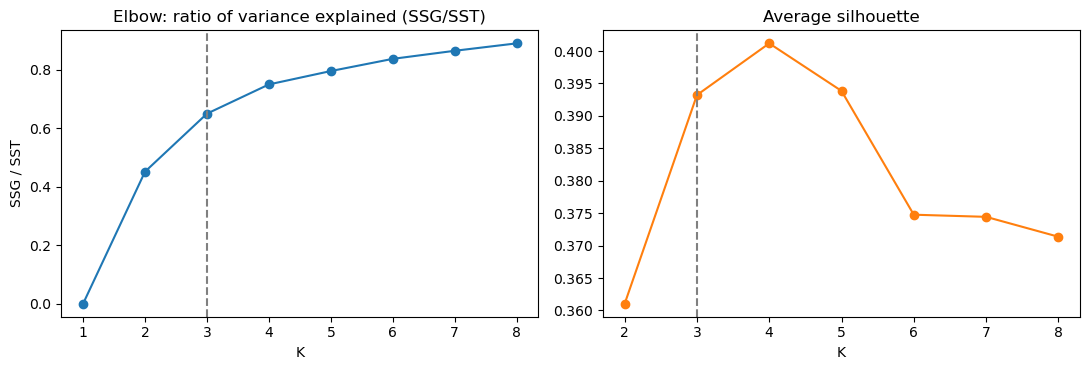

K,1,2,3,4,5,6,7,8
SSG/SST,0.0,0.45,0.65,0.75,0.80,0.84,0.86,0.89
silhouette,NaN,0.36,0.39,0.40,0.39,0.37,0.37,0.37


In [3]:
ks = range(1, 9)
res = [run(k) for k in ks]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(ks, [r[1] for r in res], "o-"); ax[0].axvline(3, ls="--", c="gray")
ax[0].set(title="Elbow: ratio of variance explained (SSG/SST)", xlabel="K", ylabel="SSG / SST")
ax[1].plot(list(ks)[1:], [r[2] for r in res][1:], "o-", c="tab:orange"); ax[1].axvline(3, ls="--", c="gray")
ax[1].set(title="Average silhouette", xlabel="K")
plt.tight_layout(); plt.show()
pd.DataFrame({"K": ks, "SSG/SST": [round(r[1], 2) for r in res], "silhouette": [round(r[2], 2) for r in res]}).set_index("K").T

## 3. Cluster centers for K = 2, 3, 4

In [4]:
for k in [2, 3, 4]:
    labels, r2, sil = run(k)
    t = df.assign(cluster=labels).groupby("cluster")
    print(f"K = {k}   SSG/SST = {r2:.2f}   silhouette = {sil:.2f}")
    display(t[VARS + ["Age", "Channel", "CLV"]].mean().round(1).assign(n=t.size()))

K = 2   SSG/SST = 0.45   silhouette = 0.36


,AOV,Months,Churn,Age,Channel,CLV,n
cluster,,,,,,,
0,81.9,25.6,1.3,36.8,1.5,7643.3,13
1,51.0,13.7,3.4,40.5,1.6,2040.3,19


K = 3   SSG/SST = 0.65   silhouette = 0.39


,AOV,Months,Churn,Age,Channel,CLV,n
cluster,,,,,,,
0,54.8,14.1,4.8,43.6,1.8,2698.5,8
1,51.6,15.4,1.9,37.6,1.5,2077.8,16
2,96.2,29.2,1.5,37.2,1.4,10411.9,8


K = 4   SSG/SST = 0.75   silhouette = 0.40


,AOV,Months,Churn,Age,Channel,CLV,n
cluster,,,,,,,
0,59.2,17.5,5.0,45.7,1.7,3551.3,6
1,55.1,17.3,1.8,38.8,1.5,2498.7,13
2,96.2,29.2,1.5,37.2,1.4,10411.9,8
3,38.6,6.0,3.2,34.2,1.8,208.4,5


## 4. Chosen solution: K = 3

K = 3 gives the largest jump in variance explained (0.45 to 0.65), and it separates **high-churn** customers from **stable low spenders**, which K = 2 lumps together. K = 4 only splits off a 5-customer group, and its silhouette barely improves.

In [5]:
labels, _, _ = run(3)
df["cluster"] = labels
prof = df.groupby("cluster")[VARS].mean()
names = {}
names[prof.AOV.idxmax()] = "Loyal high spenders"
names[prof.Churn.idxmax()] = "At-risk regulars"
names[[c for c in prof.index if c not in names][0]] = "Steady mainstream"
df["segment"] = df.cluster.map(names)
summary = df.groupby("segment")[VARS + ["Age", "Channel", "CLV", "CAC"]].mean().round(1)
summary["n"] = df.groupby("segment").size()
summary["members"] = df.groupby("segment").ID.apply(lambda s: ", ".join(map(str, s)))
summary

,AOV,Months,Churn,Age,Channel,CLV,CAC,n,members
segment,,,,,,,,,
At-risk regulars,54.8,14.1,4.8,43.6,1.8,2698.5,98.5,8,"8, 9, 12, 13, 14, 20, 23, 30"
Loyal high spenders,96.2,29.2,1.5,37.2,1.4,10411.9,113.2,8,"5, 6, 7, 11, 15, 16, 27, 32"
Steady mainstream,51.6,15.4,1.9,37.6,1.5,2077.8,84.7,16,"1, 2, 3, 4, 10, 17, 18, 19, 21, 22, 24, 25, 26..."


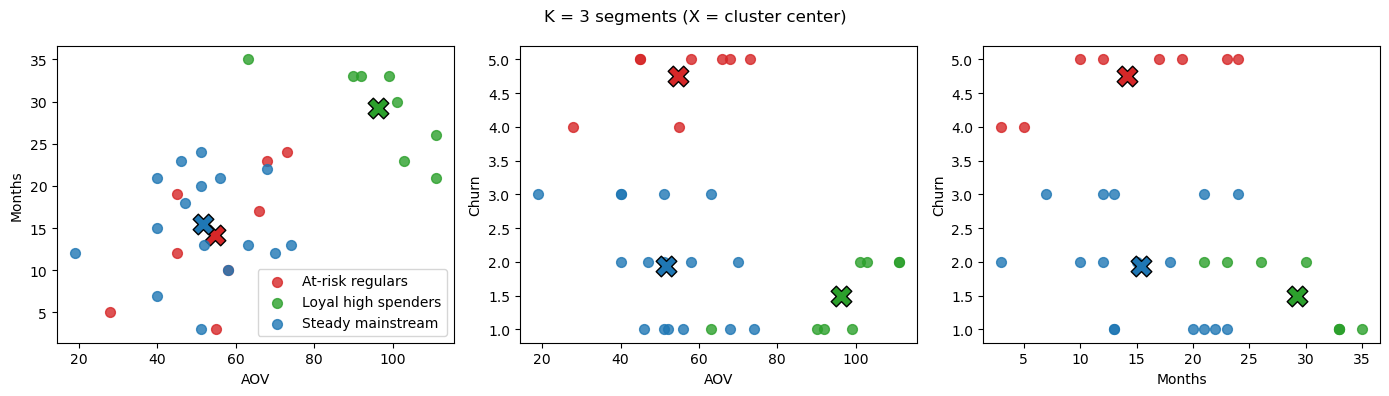

In [6]:
colors = {"Loyal high spenders": "tab:green", "Steady mainstream": "tab:blue", "At-risk regulars": "tab:red"}
pairs = [("AOV", "Months"), ("AOV", "Churn"), ("Months", "Churn")]
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (x, y) in zip(ax, pairs):
    for s, g in df.groupby("segment"):
        a.scatter(g[x], g[y], c=colors[s], label=s, s=50, alpha=.8)
        a.scatter(g[x].mean(), g[y].mean(), c=colors[s], marker="X", s=220, edgecolor="k")
    a.set(xlabel=x, ylabel=y)
ax[0].legend(); plt.suptitle("K = 3 segments (X = cluster center)"); plt.tight_layout(); plt.show()

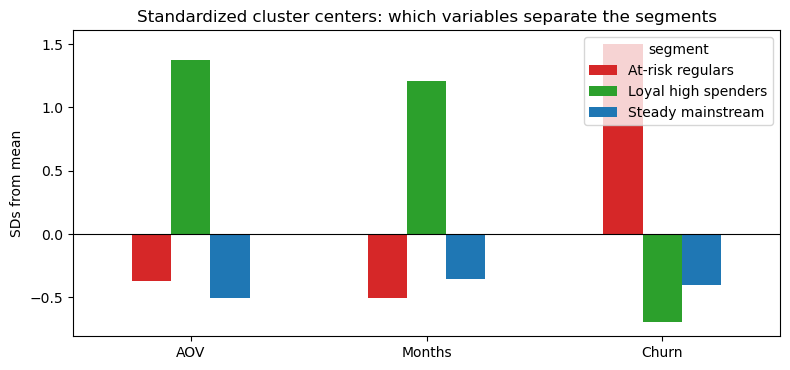

In [7]:
zc = Z.assign(segment=df.segment).groupby("segment").mean()
zc.T.plot.bar(figsize=(8, 3.8), color=[colors[s] for s in zc.index], rot=0)
plt.axhline(0, c="k", lw=.8); plt.title("Standardized cluster centers: which variables separate the segments")
plt.ylabel("SDs from mean"); plt.tight_layout(); plt.show()

## 5. Focus segment: "At-risk regulars"

These customers spend and stay about as much as the mainstream group (about \$55 per order, about 14 months), but their churn risk is very high (about 4.8 out of 5). They skew older and mostly order on the web.

**Action:** send a personalized win-back **email**, not an app push, with a "\$15 off your next 2 orders" retention credit. Loyal customers would buy anyway and steady customers aren't at risk, so the offer only makes sense for this segment.

**Assumptions:** the churn score predicts real churn, discounts reduce churn here, and email reaches web-first customers.

## 6. Reflection
Clustering on Orders, AOV and Months (the three factors in CLV) only sorts customers by value. Swapping in **Churn Risk** is what produces the at-risk segment, a group defined by future risk rather than past spend. The trade-off is that a 1–5 score has a strong pull on the clusters once it is standardized.